### Importation 

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv("../data/orig/student_mental_health.csv")
TARGET = "Mental_Health_Risk"
ORDER = ["Low", "Medium", "High"]

print(df.shape)
df.head()

(2000, 17)


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [83]:
df.info()
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [84]:
# statistiques descriptives
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = []
for c in df.columns:
    if c not in num_cols and c not in ["Student_ID", TARGET]:
        cat_cols.append(c)


display(df[num_cols].describe().T)
display(df[cat_cols + [TARGET]].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


,count,unique,top,freq
Gender,2000,3,Female,971
Physical_Activity,2000,3,Moderate,906
Part_Time_Job,2000,2,No,1289
Diet_Quality,1931,3,Average,860
Previous_Mental_Health_History,2000,2,No,1408
Mental_Health_Risk,2000,3,High,680


In [94]:
# valeurs manquantes
missing = (df.isna().sum()).round(2).sort_values(ascending=False)
missing[missing > 0]

Financial_Stress      91
Diet_Quality          69
Sleep_Hours           62
Social_Media_Hours    58
Family_Support        54
Attendance_Rate       47
GPA                   38
dtype: int64

In [86]:
# doublons et incohérences
print("Lignes dupliquées :", df.duplicated().sum())
print("Student_ID dupliqués :", df["Student_ID"].duplicated().sum())

# Min/max pour repérer les valeurs impossibles
df[num_cols].agg(["min", "max"]).T

Lignes dupliquées : 0
Student_ID dupliqués : 0


,min,max
Age,17.0,29.00
Year_of_Study,1.0,5.00
Sleep_Hours,3.3,10.00
Study_Hours_Per_Week,2.4,38.30
GPA,1.5,3.66
Social_Media_Hours,2.1,10.00
Screen_Time_Hours,3.3,14.00
Financial_Stress,1.4,10.00
Family_Support,1.7,9.90
Attendance_Rate,54.4,100.00


In [87]:
# Valeurs des colonnes catégorielles (fautes de frappe, casse...)
for c in cat_cols + [TARGET]:
    print(c, df[c].unique())

Gender <ArrowStringArray>
['Male', 'Female', 'Non-binary']
Length: 3, dtype: str
Physical_Activity <ArrowStringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str
Part_Time_Job <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
Diet_Quality <ArrowStringArray>
['Poor', 'Average', nan, 'Good']
Length: 4, dtype: str
Previous_Mental_Health_History <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
Mental_Health_Risk <ArrowStringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str


Social_Media_Hours      20
Attendance_Rate         12
GPA                      9
Study_Hours_Per_Week     7
Screen_Time_Hours        7
Age                      4
Sleep_Hours              2
Year_of_Study            0
Financial_Stress         0
Family_Support           0
dtype: int64


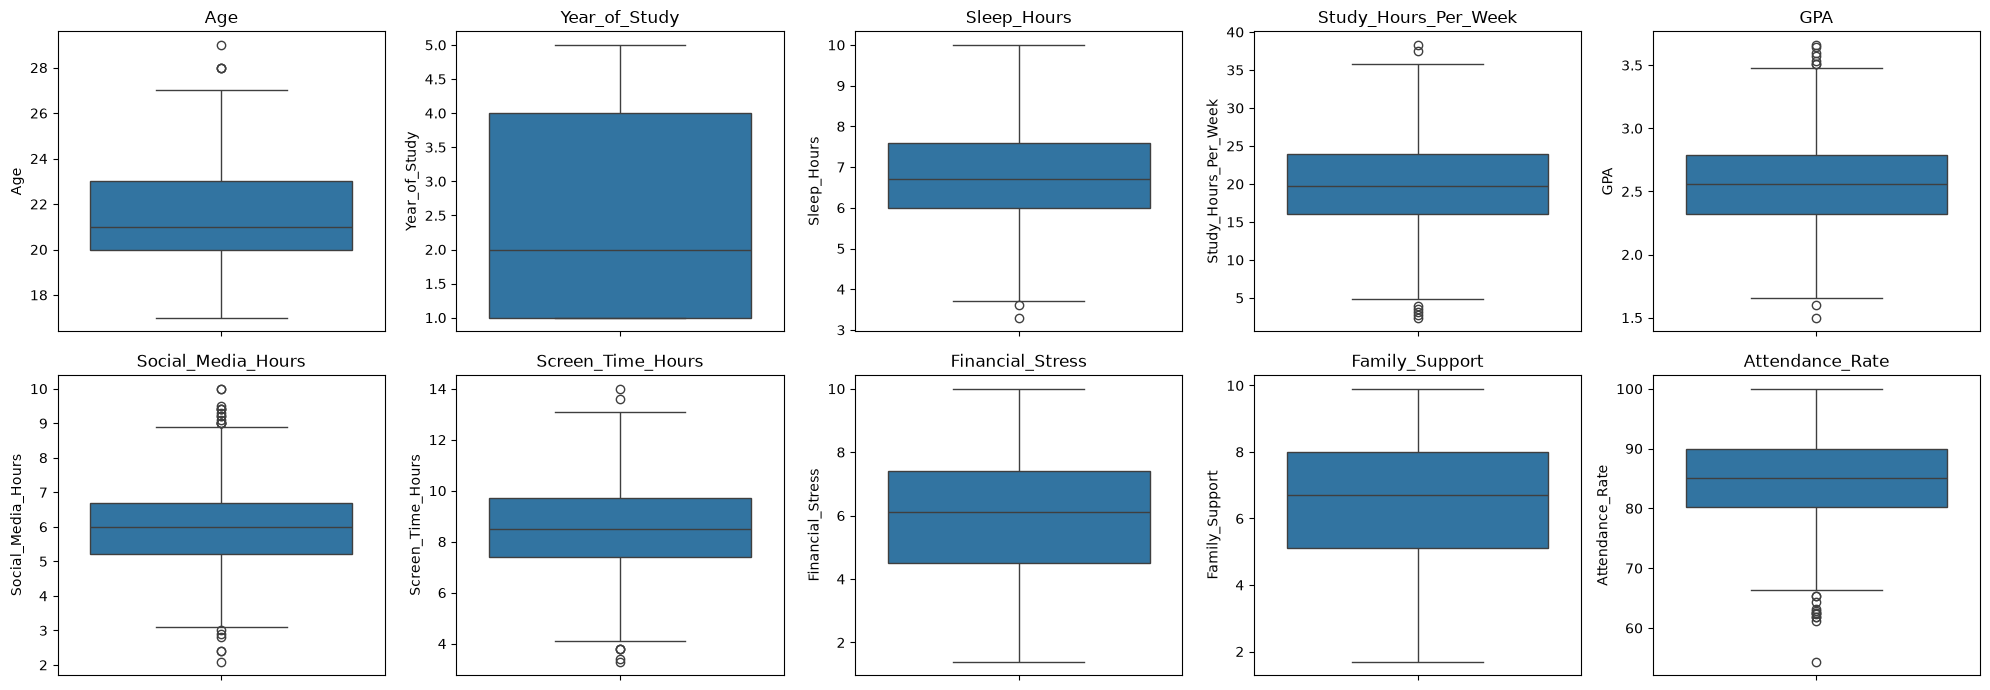

In [88]:
# valeurs aberrantes (méthode IQR) + boxplots
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print(df[num_cols].apply(iqr_outliers).sort_values(ascending=False))

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()

Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33
Name: proportion, dtype: float64


<Axes: xlabel='Mental_Health_Risk', ylabel='count'>

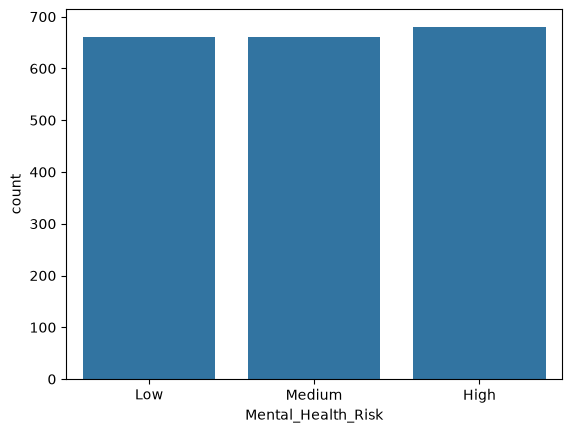

In [89]:
# distribution de la cible et déséquilibre
print(df[TARGET].value_counts(normalize=True).round(3))
sns.countplot(data=df, x=TARGET, order=ORDER)

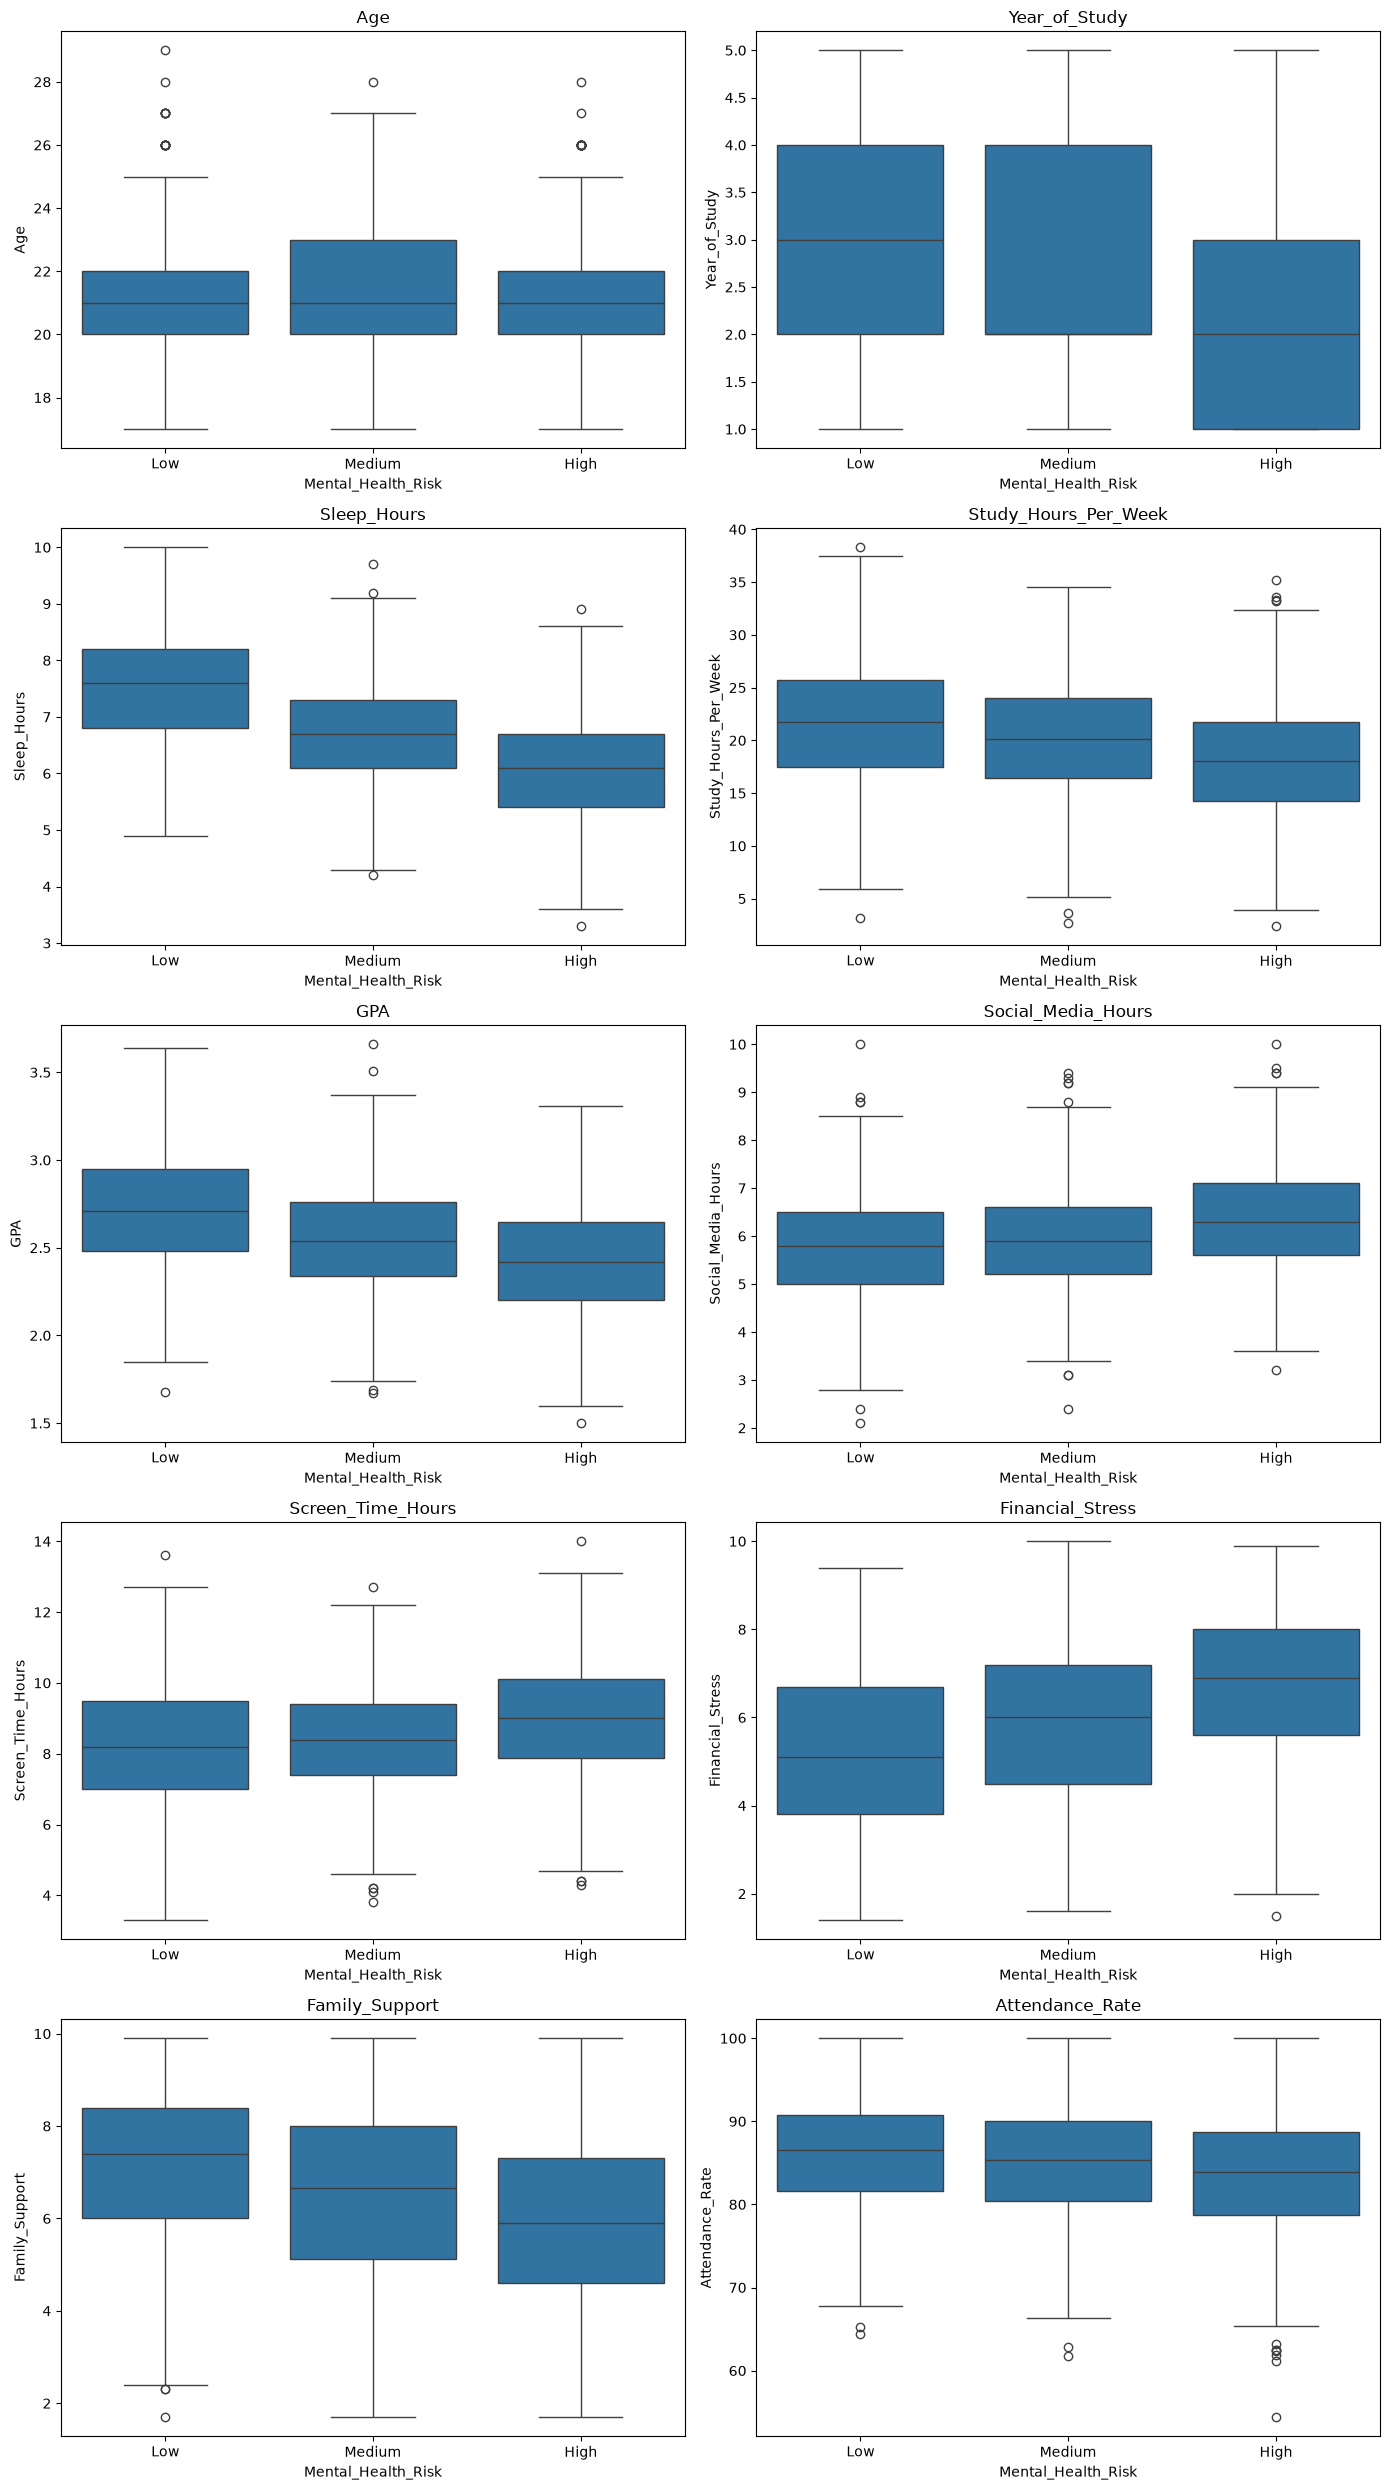

In [90]:
# variables numériques vs cible
fig, axes = plt.subplots(
    (len(num_cols) + 1) // 2,
    2,
    figsize=(14, 5 * ((len(num_cols) + 1) // 2))
)

for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, order=ORDER, ax=ax)
    ax.set_title(col)

for ax in axes.ravel()[len(num_cols):]:
    ax.remove()

plt.tight_layout()

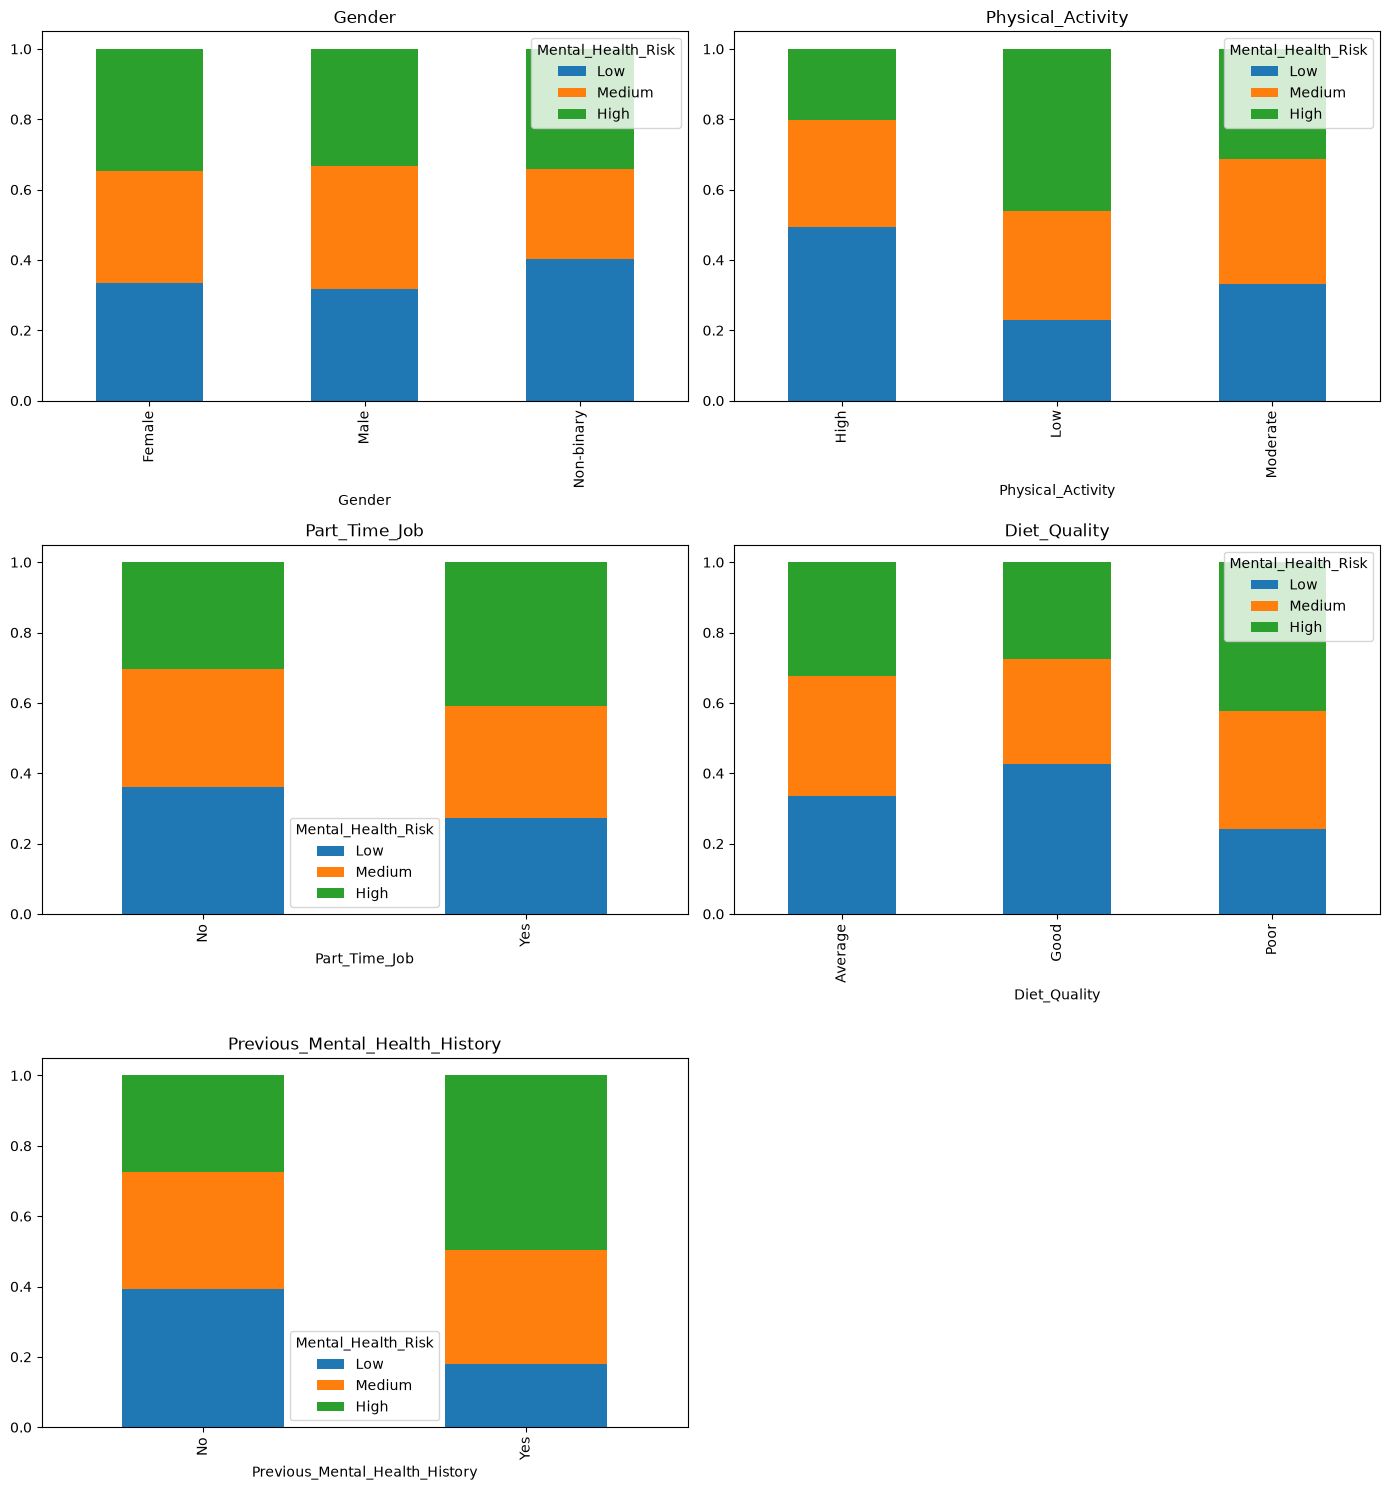

In [91]:
# variables catégorielles vs cible
fig, axes = plt.subplots(
    (len(cat_cols) + 1) // 2,
    2,
    figsize=(14, 5 * ((len(cat_cols) + 1) // 2))
)

for ax, col in zip(axes.ravel(), cat_cols):
    (pd.crosstab(df[col], df[TARGET], normalize="index")[ORDER]
       .plot(kind="bar", stacked=True, ax=ax, title=col))

for ax in axes.ravel()[len(cat_cols):]:
    ax.remove()

plt.tight_layout()

Sleep_Hours            -0.541857
GPA                    -0.352626
Financial_Stress        0.313547
Family_Support         -0.250894
Study_Hours_Per_Week   -0.238793
Social_Media_Hours      0.207601
Screen_Time_Hours       0.173972
Year_of_Study          -0.166404
Attendance_Rate        -0.145362
Age                     0.004961
Name: risk_num, dtype: float64

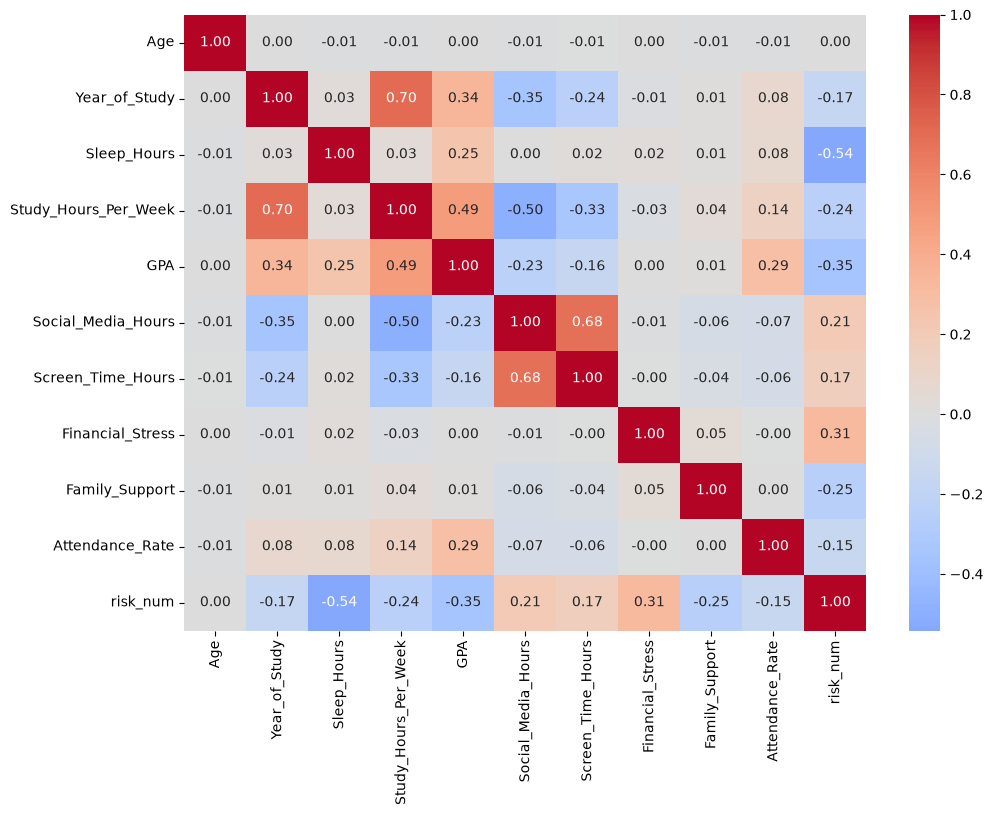

In [92]:
# corrélations
df["risk_num"] = df[TARGET].map({"Low": 0, "Medium": 1, "High": 2})
num_only = [c for c in num_cols if c != "risk_num"]

corr = df[num_only + ["risk_num"]].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)

# Variables les plus liées au risque
corr["risk_num"].drop("risk_num").sort_values(key=abs, ascending=False)

## split le dataset 

In [95]:
X = df.drop(columns=TARGET)
y =df[TARGET]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split()